# ParkVision AI — навчання детектора й OCR номерних знаків

## Запуск
На Windows використовуйте kernel `WS\.venv\Scripts\python.exe`. Залежності notebook уже включені в `requirements.txt`. Розмістіть `elpd.zip` у `data/raw/elpd.zip` або розпакуйте в `data/raw/elpd/`. Виконайте клітинки послідовно. Навчання на CPU може тривати довго; розмір даних, batch та кількість епох змінюються в конфігураційній клітинці.

In [1]:
import hashlib
import json
import math
import os
import random
import shutil
import sys
import zipfile
from functools import lru_cache
from pathlib import Path

EXPECTED_VENV = (Path.cwd() / '.venv').resolve()
EXPECTED_PYTHON = EXPECTED_VENV / ('Scripts/python.exe' if os.name == 'nt' else 'bin/python')
if EXPECTED_VENV.is_dir() and Path(sys.prefix).resolve() != EXPECTED_VENV:
    raise RuntimeError('Wrong notebook kernel. In VS Code select Python (ParkVision WS): ' + str(EXPECTED_PYTHON))
os.environ.setdefault('YOLO_CONFIG_DIR', str(Path.cwd() / '.ultralytics'))

import cv2
import numpy as np
import tensorflow as tf
import yaml
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from ultralytics import YOLO
import torch

try:
    tf.config.threading.set_intra_op_parallelism_threads(min(8, os.cpu_count() or 1))
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass

ROOT = Path.cwd().resolve()
RAW_DIR = ROOT / 'data' / 'raw' / 'elpd'
ELPD_ARCHIVE = ROOT / 'data' / 'raw' / 'elpd.zip'
MODEL_DIR = ROOT / 'data' / 'models'
DETECTOR_OUTPUT = MODEL_DIR / 'lpr_training'
OCR_OUTPUT = MODEL_DIR / 'ocr_training'
DETECTOR_PATH = MODEL_DIR / 'lpr_detector.pt'
OCR_PATH = MODEL_DIR / 'ukrainian_lp_sequence_model.keras'
VOCAB_PATH = MODEL_DIR / 'ukrainian_lp_characters.json'
SEED = 42
IMAGE_SIZE = 640
DETECTOR_EPOCHS = 30
DETECTOR_BATCH = 4
OCR_HEIGHT, OCR_WIDTH = 48, 144
OCR_BATCH = 128
OCR_EPOCHS = 25
OCR_TRAIN_COUNT = 12000
OCR_VALID_COUNT = 1500
OCR_TEST_COUNT = 2000
TARGET_PLATE_EXACT_MATCH = 0.85
TRAIN_DETECTOR = True
TRAIN_OCR = True

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print('Project:', ROOT)
print('Python:', sys.executable)
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))
print('Torch CUDA:', torch.cuda.is_available())

Project: C:\Users\Admin\Desktop\Programming\telegram\WS
Python: c:\Users\Admin\Desktop\Programming\telegram\WS\.venv\Scripts\python.exe
TensorFlow: 2.21.0 | GPU: []
Torch CUDA: False


## 1. Перевірка ELPD та незалежний split для детектора

In [2]:
def safe_extract_zip(archive: Path, destination: Path, max_unpacked_bytes=20 * 1024**3):
    destination.mkdir(parents=True, exist_ok=True)
    root = destination.resolve()
    with zipfile.ZipFile(archive) as zf:
        members = zf.infolist()
        if sum(member.file_size for member in members) > max_unpacked_bytes:
            raise ValueError('ELPD archive exceeds the configured extraction limit')
        for member in members:
            target = (destination / member.filename).resolve()
            if target != root and root not in target.parents:
                raise ValueError(f'Unsafe archive path: {member.filename}')
        zf.extractall(destination)

if not RAW_DIR.exists() or not any(RAW_DIR.rglob('images')):
    if not ELPD_ARCHIVE.is_file():
        raise FileNotFoundError(f'Place ELPD at {ELPD_ARCHIVE} or extract it under {RAW_DIR}')
    safe_extract_zip(ELPD_ARCHIVE, RAW_DIR)

dataset_roots = [p.parent for p in RAW_DIR.rglob('images') if (p.parent / 'labels').is_dir()]
if not dataset_roots:
    raise FileNotFoundError('Expected a YOLO dataset with sibling images/ and labels/ folders')
DATASET_ROOT = sorted(dataset_roots, key=lambda path: len(path.parts))[0]
IMAGE_ROOT, LABEL_ROOT = DATASET_ROOT / 'images', DATASET_ROOT / 'labels'
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
valid_pairs, missing_labels, unreadable, invalid_labels = [], [], [], []
seen_image_hashes = set()
duplicate_images = 0
for image_path in sorted(p for p in IMAGE_ROOT.rglob('*') if p.suffix.lower() in IMAGE_SUFFIXES):
    label_path = LABEL_ROOT / image_path.relative_to(IMAGE_ROOT).with_suffix('.txt')
    if not label_path.is_file():
        missing_labels.append(image_path.name)
        continue
    image_bytes = image_path.read_bytes()
    image = cv2.imdecode(np.frombuffer(image_bytes, dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None or image.size == 0:
        unreadable.append(image_path.name)
        continue
    label_lines = [line.split() for line in label_path.read_text(encoding='utf-8').splitlines() if line.strip()]
    good = bool(label_lines)
    for line_number, fields in enumerate(label_lines, start=1):
        try:
            values = np.asarray([float(value) for value in fields], dtype=np.float64)
            line_ok = len(values) == 5 and values[0] == 0 and np.isfinite(values).all() and np.all((values[1:] >= 0) & (values[1:] <= 1)) and values[3] > 0 and values[4] > 0
        except (ValueError, TypeError):
            line_ok = False
        if not line_ok:
            invalid_labels.append(f'{label_path}:{line_number}')
            good = False
            break
    if not good:
        continue
    digest = hashlib.sha256(image_bytes).hexdigest()
    if digest in seen_image_hashes:
        duplicate_images += 1
        continue
    seen_image_hashes.add(digest)
    valid_pairs.append((image_path.resolve(), label_path.resolve(), digest))

if invalid_labels:
    raise ValueError('Invalid YOLO label, first example: ' + invalid_labels[0])
if len(valid_pairs) < 100:
    raise ValueError(f'Only {len(valid_pairs)} valid labelled images; expected at least 100')
random.Random(SEED).shuffle(valid_pairs)
n_train, n_val = round(len(valid_pairs) * .70), round(len(valid_pairs) * .15)
detector_splits = {'train': valid_pairs[:n_train], 'val': valid_pairs[n_train:n_train+n_val], 'test': valid_pairs[n_train+n_val:]}
SPLIT_DIR = RAW_DIR / 'parkvision_split'
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
for split_name, pairs in detector_splits.items():
    (SPLIT_DIR / f'{split_name}.txt').write_text('\n'.join(str(image) for image, _, _ in pairs) + '\n', encoding='utf-8')
fingerprint = hashlib.sha256('\n'.join(digest for _, _, digest in valid_pairs).encode()).hexdigest()
detector_manifest = {'seed': SEED, 'counts': {name: len(rows) for name, rows in detector_splits.items()}, 'valid_images': len(valid_pairs), 'missing_labels': len(missing_labels), 'unreadable': len(unreadable), 'duplicate_images_skipped': duplicate_images, 'sha256': fingerprint}
(SPLIT_DIR / 'manifest.json').write_text(json.dumps(detector_manifest, indent=2), encoding='utf-8')
DATA_YAML = SPLIT_DIR / 'data.yaml'
DATA_YAML.write_text(yaml.safe_dump({'path': str(DATASET_ROOT), 'train': str(SPLIT_DIR / 'train.txt'), 'val': str(SPLIT_DIR / 'val.txt'), 'test': str(SPLIT_DIR / 'test.txt'), 'nc': 1, 'names': ['license_plate']}, sort_keys=False), encoding='utf-8')
print('Valid labeled images:', len(valid_pairs), '| split:', detector_manifest['counts'])
print('Missing labels:', len(missing_labels), '| unreadable:', len(unreadable), '| invalid:', len(invalid_labels))
print('Dataset SHA-256:', fingerprint)

Valid labeled images: 2285 | split: {'train': 1600, 'val': 343, 'test': 342}
Missing labels: 43 | unreadable: 1 | invalid: 0
Dataset SHA-256: 58808411f7c9cafaf267df5412231f052f41843ace9cd03595c1539ed2b0c1c5


## 2. Навчання та оцінювання детектора номерного знака

In [3]:
BASE_WEIGHTS = ROOT / 'yolov8n.pt'
if TRAIN_DETECTOR:
    if not BASE_WEIGHTS.is_file():
        raise FileNotFoundError(f'YOLO base weights missing: {BASE_WEIGHTS}')
    detector = YOLO(str(BASE_WEIGHTS))
    device = 0 if torch.cuda.is_available() else 'cpu'
    detector.train(data=str(DATA_YAML), epochs=DETECTOR_EPOCHS, imgsz=IMAGE_SIZE, batch=DETECTOR_BATCH, workers=0, device=device, seed=SEED, deterministic=True, patience=8, project=str(DETECTOR_OUTPUT), name='elpd_plate_detector', exist_ok=True, plots=True, verbose=True)
    best_detector = DETECTOR_OUTPUT / 'elpd_plate_detector' / 'weights' / 'best.pt'
    if not best_detector.is_file():
        raise FileNotFoundError(f'Detector training did not produce {best_detector}')
    detector = YOLO(str(best_detector))
    detector_metrics = detector.val(data=str(DATA_YAML), split='test', imgsz=IMAGE_SIZE, device=device, plots=True, project=str(DETECTOR_OUTPUT), name='elpd_plate_test', exist_ok=True)
    shutil.copy2(best_detector, DETECTOR_PATH)
    detector_report = {'dataset': 'ELPD synthetic', 'split': 'test', 'precision': float(detector_metrics.box.mp), 'recall': float(detector_metrics.box.mr), 'map50': float(detector_metrics.box.map50), 'map50_95': float(detector_metrics.box.map), 'weights': str(DETECTOR_PATH)}
    (MODEL_DIR / 'lpr_test_metrics.json').write_text(json.dumps(detector_report, indent=2), encoding='utf-8')
    print(json.dumps(detector_report, indent=2))
else:
    if not DETECTOR_PATH.is_file():
        raise FileNotFoundError(f'Existing detector weights missing: {DETECTOR_PATH}')
    print('Detector training skipped; using existing:', DETECTOR_PATH)

New https://pypi.org/project/ultralytics/8.4.219 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.208  Python-3.13.14 torch-2.15.0+cpu CPU (12th Gen Intel Core i5-12500H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Admin\Desktop\Programming\telegram\WS\data\raw\elpd\parkvision_split\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4

## 3. Генератор OCR-даних українських номерів
Використовується 8 позицій `LLDDDDLL`: дві літери, чотири цифри, дві літери. Алфавіт містить лише символи, допустимі в українських номерних знаках і в поточному веб-OCR. Номер не може потрапити одночасно в різні split-вибірки.

OCR alphabet: 0123456789ABCEHIKMOPTX | classes: 22
Font candidates: ['arial.ttf', 'arialbd.ttf', 'bahnschrift.ttf']
Sample generated labels: ['OA9729XM', 'AH8056EH', 'OI9782CX', 'II9398HM']


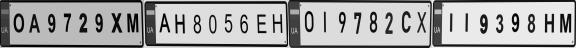

In [4]:
from PIL import Image, ImageDraw, ImageFont

DIGITS = '0123456789'
PLATE_LETTERS = 'ABCEHIKMOPTX'
PLATE_ALPHABET = DIGITS + PLATE_LETTERS
PLATE_LENGTH = 8
assert len(PLATE_ALPHABET) == 22 and len(set(PLATE_ALPHABET)) == 22
CHAR_TO_ID = {char: index for index, char in enumerate(PLATE_ALPHABET)}
CANVAS_W, CANVAS_H = 720, 144

font_roots = []
if os.name == 'nt':
    font_roots.append(Path(os.environ.get('WINDIR', r'C:\\Windows')) / 'Fonts')
font_roots.extend([Path('/usr/share/fonts/truetype'), Path('/usr/local/share/fonts'), Path('/System/Library/Fonts')])
preferred_font_names = {'arialbd.ttf', 'arial.ttf', 'ARIALNB.TTF', 'bahnschrift.ttf', 'dejavusanscondensed-bold.ttf', 'liberationsans-bold.ttf'}
font_files = sorted({str(path) for root in font_roots if root.exists() for path in root.rglob('*.ttf') if path.name.lower() in preferred_font_names})
if not font_files:
    font_files = sorted({str(path) for root in font_roots if root.exists() for path in root.rglob('*.ttf')})[:12]
if not font_files:
    raise RuntimeError('No TrueType fonts found. Install Arial/DejaVu/Liberation Sans before generating OCR data.')
print('OCR alphabet:', PLATE_ALPHABET, '| classes:', len(PLATE_ALPHABET))
print('Font candidates:', [Path(path).name for path in font_files])

@lru_cache(maxsize=256)
def get_font(path, size):
    return ImageFont.truetype(path, size=size)

def make_plate_text(rng):
    return ''.join(rng.choice(PLATE_LETTERS) for _ in range(2)) + ''.join(rng.choice(DIGITS) for _ in range(4)) + ''.join(rng.choice(PLATE_LETTERS) for _ in range(2))

def make_unique_plate_lists(counts, seed=SEED):
    rng, used, result = random.Random(seed), set(), []
    for count in counts:
        split = []
        while len(split) < count:
            plate = make_plate_text(rng)
            if plate not in used:
                used.add(plate)
                split.append(plate)
        result.append(split)
    return result

def render_plate(plate, rng, training=True):
    if len(plate) != PLATE_LENGTH or any(char not in CHAR_TO_ID for char in plate):
        raise ValueError(f'Invalid plate text: {plate}')
    background = rng.randint(232, 255)
    image = Image.new('RGB', (CANVAS_W, CANVAS_H), (background, background, background))
    draw = ImageDraw.Draw(image)
    frame = rng.randint(4, 8)
    draw.rounded_rectangle((2, 2, CANVAS_W-3, CANVAS_H-3), radius=12, outline=(15, 20, 25), width=frame)
    stripe_w = rng.randint(48, 58)
    draw.rectangle((frame, frame, stripe_w, CANVAS_H-frame), fill=(25, 70, 150))
    draw.rectangle((frame+4, 30, stripe_w-4, 43), fill=(245, 195, 35))
    draw.rectangle((frame+4, 44, stripe_w-4, 57), fill=(30, 75, 165))
    stripe_font = get_font(font_files[0], 23)
    draw.text((stripe_w/2, 92), 'UA', font=stripe_font, anchor='mm', fill=(255, 255, 255))
    font_path = rng.choice(font_files)
    font_size = rng.randint(68, 86)
    font = get_font(font_path, font_size)
    group_gap = rng.uniform(5.0, 11.0)
    slot_start = stripe_w + 9
    available = CANVAS_W - slot_start - 12
    slot_width = (available - 2*group_gap) / PLATE_LENGTH
    widths = [draw.textlength(char, font=font) for char in plate]
    while max(widths) > slot_width*.88 and font_size > 48:
        font_size -= 2
        font = get_font(font_path, font_size)
        widths = [draw.textlength(char, font=font) for char in plate]
    if max(widths) > slot_width:
        raise ValueError('Chosen font glyph is too wide for one plate character slot')
    for index, char in enumerate(plate):
        center_x = slot_start + slot_width*(index+.5) + (group_gap if index >= 2 else 0) + (group_gap if index >= 6 else 0)
        center_y = CANVAS_H/2 + rng.uniform(-2.5, 2.5)
        draw.text((int(center_x), int(center_y)), char, font=font, anchor='mm', fill=(rng.randint(0, 35),)*3, stroke_width=rng.choice([0, 0, 1]), stroke_fill=(0, 0, 0))
    for screw_x in (stripe_w+5, CANVAS_W-18):
        screw_y = rng.choice((17, CANVAS_H-18))
        draw.ellipse((screw_x-3, screw_y-3, screw_x+3, screw_y+3), fill=(120, 125, 130))
    rgb = np.asarray(image, dtype=np.uint8)
    if training:
        corners = np.float32([[0,0],[CANVAS_W-1,0],[CANVAS_W-1,CANVAS_H-1],[0,CANVAS_H-1]])
        jitter = np.float32([[rng.uniform(-6,6),rng.uniform(-4,4)] for _ in range(4)])
        transform = cv2.getPerspectiveTransform(corners, corners+jitter)
        rgb = cv2.warpPerspective(rgb, transform, (CANVAS_W,CANVAS_H), borderMode=cv2.BORDER_CONSTANT, borderValue=(245,245,245))
        if rng.random() < .25:
            rgb = cv2.GaussianBlur(rgb, (3,3), rng.uniform(.2, .9))
        if rng.random() < .12:
            noise = np.random.default_rng(rng.randrange(2**32)).normal(0, rng.uniform(1, 8), rgb.shape)
            rgb = np.clip(rgb.astype(np.float32)+noise, 0, 255).astype(np.uint8)
        if rng.random() < .18:
            ok, encoded = cv2.imencode('.jpg', rgb, [cv2.IMWRITE_JPEG_QUALITY, rng.randint(40, 88)])
            if ok:
                rgb = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
                rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)
        alpha, beta = rng.uniform(.78, 1.2), rng.uniform(-18, 18)
        rgb = np.clip(rgb.astype(np.float32)*alpha+beta, 0, 255).astype(np.uint8)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    gray = cv2.resize(gray, (OCR_WIDTH, OCR_HEIGHT), interpolation=cv2.INTER_AREA)
    return gray[..., None]

preview_rng = random.Random(SEED+99)
preview_texts = [make_plate_text(preview_rng) for _ in range(4)]
preview = np.concatenate([np.repeat(render_plate(text, preview_rng)[..., :], 3, axis=2) for text in preview_texts], axis=1)
print('Sample generated labels:', preview_texts)
display(Image.fromarray(preview))

## 4. Формування незалежних OCR train/validation/test наборів і CNN

In [5]:
def make_ocr_arrays(plates, seed, training):
    rng = random.Random(seed)
    images = np.empty((len(plates), OCR_HEIGHT, OCR_WIDTH, 1), dtype=np.uint8)
    labels = np.empty((len(plates), PLATE_LENGTH), dtype=np.int32)
    for index, plate in enumerate(plates):
        images[index] = render_plate(plate, rng, training=training)
        labels[index] = [CHAR_TO_ID[char] for char in plate]
        if index and index % 5000 == 0:
            print(f'Generated {index:,}/{len(plates):,}')
    return images, labels

ocr_plate_splits = make_unique_plate_lists([OCR_TRAIN_COUNT, OCR_VALID_COUNT, OCR_TEST_COUNT], SEED+1)
assert not (set(ocr_plate_splits[0]) & set(ocr_plate_splits[1]))
assert not (set(ocr_plate_splits[0]) & set(ocr_plate_splits[2]))
assert not (set(ocr_plate_splits[1]) & set(ocr_plate_splits[2]))
X_train, y_train = make_ocr_arrays(ocr_plate_splits[0], SEED+11, training=True)
X_valid, y_valid = make_ocr_arrays(ocr_plate_splits[1], SEED+22, training=False)
X_test, y_test = make_ocr_arrays(ocr_plate_splits[2], SEED+33, training=False)
print('OCR arrays:', X_train.shape, X_valid.shape, X_test.shape)
print('Train/validation/test plate IDs are disjoint.')

def build_ocr_model():
    augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomContrast(.22),
        tf.keras.layers.RandomRotation(.018, fill_mode='constant', fill_value=1.0),
        tf.keras.layers.RandomTranslation(.035, .045, fill_mode='constant', fill_value=1.0),
        tf.keras.layers.RandomBrightness(.12, value_range=(0,1)),
    ], name='plate_augmentation')
    inputs = tf.keras.Input(shape=(OCR_HEIGHT, OCR_WIDTH, 1), name='gray_plate')
    x = tf.keras.layers.Rescaling(1./255)(inputs)
    x = augmentation(x)
    for filters, pool_size in ((16, (2,2)), (32, (2,2)), (64, (2,1)), (96, (2,1))):
        x = tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation('relu')(x)
        x = tf.keras.layers.MaxPooling2D(pool_size=pool_size)(x)
    x = tf.keras.layers.Conv2D(128, 3, padding='same', activation='relu')(x)
    x = tf.keras.layers.Resizing(1, PLATE_LENGTH, interpolation='bilinear')(x)
    x = tf.keras.layers.Reshape((PLATE_LENGTH, 128))(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dropout(.15)(x)
    outputs = tf.keras.layers.Dense(len(PLATE_ALPHABET), activation='softmax', name='character_probabilities')(x)
    model = tf.keras.Model(inputs, outputs, name='ukrainian_plate_ocr')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='character_accuracy')])
    return model

ocr_model = build_ocr_model()
ocr_model.summary()

Generated 5,000/12,000
Generated 10,000/12,000
OCR arrays: (12000, 48, 144, 1) (1500, 48, 144, 1) (2000, 48, 144, 1)
Train/validation/test plate IDs are disjoint.


Model: "ukrainian_plate_ocr"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gray_plate (InputLayer)         │ (None, 48, 144, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 48, 144, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ plate_augmentation (Sequential) │ (None, 48, 144, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 144, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 144, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 144, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 72, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 72, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 72, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 24, 72, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 36, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 36, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 12, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 36, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 6, 36, 96)      │        55,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 6, 36, 96)      │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 6, 36, 96)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 36, 96)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 3, 36, 128)     │       110,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 1, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8, 128)         │        16,51

 Total params: 209,382 (817.90 KB)

 Trainable params: 208,966 (816.27 KB)

 Non-trainable params: 416 (1.62 KB)

## 5. Навчання OCR, test-метрики та сумісні ваги вебзастосунку

In [6]:
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(min(len(X_train), 12000), seed=SEED, reshuffle_each_iteration=True).batch(OCR_BATCH).prefetch(tf.data.AUTOTUNE)
valid_ds = tf.data.Dataset.from_tensor_slices((X_valid, y_valid)).batch(OCR_BATCH).prefetch(tf.data.AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(OCR_BATCH).prefetch(tf.data.AUTOTUNE)

if TRAIN_OCR:
    OCR_OUTPUT.mkdir(parents=True, exist_ok=True)
    checkpoint_path = OCR_OUTPUT / 'best_ocr.keras'
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(str(checkpoint_path), monitor='val_loss', save_best_only=True),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=.5, patience=3, min_lr=1e-6),
    ]
    history = ocr_model.fit(train_ds, validation_data=valid_ds, epochs=OCR_EPOCHS, callbacks=callbacks, verbose=1, shuffle=False)
    if checkpoint_path.is_file():
        ocr_model = tf.keras.models.load_model(checkpoint_path)
else:
    if not OCR_PATH.is_file() or not VOCAB_PATH.is_file():
        raise FileNotFoundError('TRAIN_OCR=False requires an already trained OCR model and vocabulary.')
    saved_characters = json.loads(VOCAB_PATH.read_text(encoding='utf-8'))['characters']
    if saved_characters != PLATE_ALPHABET:
        raise ValueError('Existing OCR model uses a different alphabet. Set TRAIN_OCR=True to train the current format.')
    ocr_model = tf.keras.models.load_model(OCR_PATH)
    if ocr_model.output_shape != (None, PLATE_LENGTH, len(PLATE_ALPHABET)):
        raise ValueError('Existing OCR model output shape is incompatible with the Ukrainian plate alphabet.')

test_probabilities = ocr_model.predict(test_ds, verbose=1)
test_prediction_ids = np.argmax(test_probabilities, axis=-1)
character_accuracy = float(np.mean(test_prediction_ids == y_test))
plate_exact_match = float(np.mean(np.all(test_prediction_ids == y_test, axis=1)))

def edit_distance(left, right):
    previous = list(range(len(right)+1))
    for i, a in enumerate(left, start=1):
        current = [i]
        for j, b in enumerate(right, start=1):
            current.append(min(current[-1]+1, previous[j]+1, previous[j-1]+(a != b)))
        previous = current
    return previous[-1]

predicted_plates = [''.join(PLATE_ALPHABET[index] for index in row) for row in test_prediction_ids]
true_plates = [''.join(PLATE_ALPHABET[index] for index in row) for row in y_test]
total_edits = sum(edit_distance(truth, pred) for truth, pred in zip(true_plates, predicted_plates))
character_error_rate = total_edits / (len(true_plates)*PLATE_LENGTH)
confusion = np.zeros((len(PLATE_ALPHABET), len(PLATE_ALPHABET)), dtype=np.int64)
np.add.at(confusion, (y_test.ravel(), test_prediction_ids.ravel()), 1)
report = {'dataset': 'generated Ukrainian-format plates (synthetic only)', 'train_plates': OCR_TRAIN_COUNT, 'validation_plates': OCR_VALID_COUNT, 'test_plates': len(true_plates), 'epochs_requested': OCR_EPOCHS, 'character_accuracy': character_accuracy, 'plate_exact_match': plate_exact_match, 'character_error_rate': float(character_error_rate), 'target_exact_match': TARGET_PLATE_EXACT_MATCH, 'target_met_on_synthetic_test': plate_exact_match >= TARGET_PLATE_EXACT_MATCH, 'real_camera_accuracy_verified': False}
print(json.dumps(report, indent=2))
print('Examples (truth -> prediction):', list(zip(true_plates[:12], predicted_plates[:12])))
if plate_exact_match >= TARGET_PLATE_EXACT_MATCH:
    print('PASS: 85%+ exact-match on the generated held-out test split.')
else:
    print('NOT YET: synthetic test exact-match is below 85%; increase data/epochs or improve augmentations, then retrain. This is not a real-camera score.')

MODEL_DIR.mkdir(parents=True, exist_ok=True)
ocr_model.save(OCR_PATH)
VOCAB_PATH.write_text(json.dumps({'characters': PLATE_ALPHABET, 'format': 'LLDDDDLL'}, indent=2), encoding='utf-8')
(MODEL_DIR / 'ocr_test_metrics.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
np.savetxt(MODEL_DIR / 'ocr_character_confusion.csv', confusion, delimiter=',', fmt='%d', header=','.join(PLATE_ALPHABET), comments='')
assert ocr_model.input_shape == (None, OCR_HEIGHT, OCR_WIDTH, 1)
assert ocr_model.output_shape == (None, PLATE_LENGTH, len(PLATE_ALPHABET))
print('Saved web-compatible OCR model:', OCR_PATH)
print('Saved vocabulary:', VOCAB_PATH)

Epoch 1/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 408ms/step - character_accuracy: 0.6456 - loss: 1.1583 - val_character_accuracy: 0.0417 - val_loss: 4.4357 - learning_rate: 0.0010
Epoch 2/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 36s 385ms/step - character_accuracy: 0.9287 - loss: 0.2347 - val_character_accuracy: 0.0487 - val_loss: 6.0073 - learning_rate: 0.0010
Epoch 3/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 36s 380ms/step - character_accuracy: 0.9610 - loss: 0.1278 - val_character_accuracy: 0.3523 - val_loss: 2.4730 - learning_rate: 0.0010
Epoch 4/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 36s 383ms/step - character_accuracy: 0.9738 - loss: 0.0856 - val_character_accuracy: 0.9181 - val_loss: 0.2353 - learning_rate: 0.0010
Epoch 5/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 36s 383ms/step - character_accuracy: 0.9793 - loss: 0.0672 - val_character_accuracy: 0.9769 - val_loss: 0.0707 - learning_rate: 0.0010
Epoch 6/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 36s 382ms/step - character_accuracy: 0.9808 - loss: 0.0610 - val_character_accuracy: 0.9912 - val

## 6. Перевірка на реальних номерних знаках (необов'язково, але необхідно для реальної точності)
Покладіть **окремі crops лише номерної таблички** в `data/real_ocr_test/` і створіть поруч `labels.csv` з колонками `filename,plate`. Це має бути відкладений набір, якого немає в синтетичному навчанні; перевірте дозвіл на обробку. Клітинка не додає ці зображення до навчання й рахує реальні character accuracy, exact-match та CER. Не заявляйте 85% на реальних авто, якщо метрика цього набору нижча.

In [7]:
import csv

REAL_TEST_DIR = ROOT / 'data' / 'real_ocr_test'
REAL_LABELS = REAL_TEST_DIR / 'labels.csv'
if not REAL_LABELS.is_file():
    print('Real OCR test not present. Synthetic metrics above do not estimate camera performance.')
else:
    real_images, real_truth = [], []
    with REAL_LABELS.open(encoding='utf-8-sig', newline='') as file:
        for row in csv.DictReader(file):
            plate = row['plate'].strip().upper().replace(' ', '').replace('-', '')
            image_path = (REAL_TEST_DIR / row['filename']).resolve()
            if REAL_TEST_DIR.resolve() not in image_path.parents:
                raise ValueError('A test filename points outside data/real_ocr_test')
            valid_format = len(plate) == PLATE_LENGTH and all(ch in PLATE_LETTERS for ch in plate[:2] + plate[6:]) and all(ch in DIGITS for ch in plate[2:6])
            if not valid_format or any(ch not in CHAR_TO_ID for ch in plate):
                raise ValueError(f'Invalid Ukrainian plate label: {plate}')
            gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
            if gray is None:
                raise FileNotFoundError(image_path)
            gray = cv2.resize(gray, (OCR_WIDTH, OCR_HEIGHT), interpolation=cv2.INTER_AREA)
            real_images.append(gray[..., None])
            real_truth.append(plate)
    if not real_truth:
        raise ValueError('The real OCR test labels.csv contains no samples.')
    real_x = np.asarray(real_images, dtype=np.uint8)
    real_probs = ocr_model.predict(real_x, batch_size=OCR_BATCH, verbose=0)
    real_pred = [''.join(PLATE_ALPHABET[i] for i in row) for row in np.argmax(real_probs, axis=-1)]
    real_exact = float(np.mean([a == b for a, b in zip(real_truth, real_pred)]))
    real_char = float(np.mean([[a == b for a,b in zip(t,p)] for t,p in zip(real_truth,real_pred)]))
    real_cer = sum(edit_distance(t,p) for t,p in zip(real_truth,real_pred))/(len(real_truth)*PLATE_LENGTH)
    print(json.dumps({'real_test_count': len(real_truth), 'character_accuracy': real_char, 'plate_exact_match': real_exact, 'character_error_rate': real_cer, 'target_85_percent_met': real_exact >= TARGET_PLATE_EXACT_MATCH}, indent=2))
    print('Examples (truth -> prediction):', list(zip(real_truth[:20], real_pred[:20])))

Real OCR test not present. Synthetic metrics above do not estimate camera performance.


## 7. End-to-end preview: рамка детектора та OCR-транскрипція
Остання клітинка використовує відкладені ELPD зображення, знаходить номер і показує результат через ту саму функцію `recognize_plate`, яку викликає вебзастосунок. Текст на ELPD не має ground-truth транскрипції, тому це демонстрація pipeline, а не оцінка OCR-якості.

Plate box confidence 91.7%. Recognized plate: HO5I422P - character confidence 80.9%


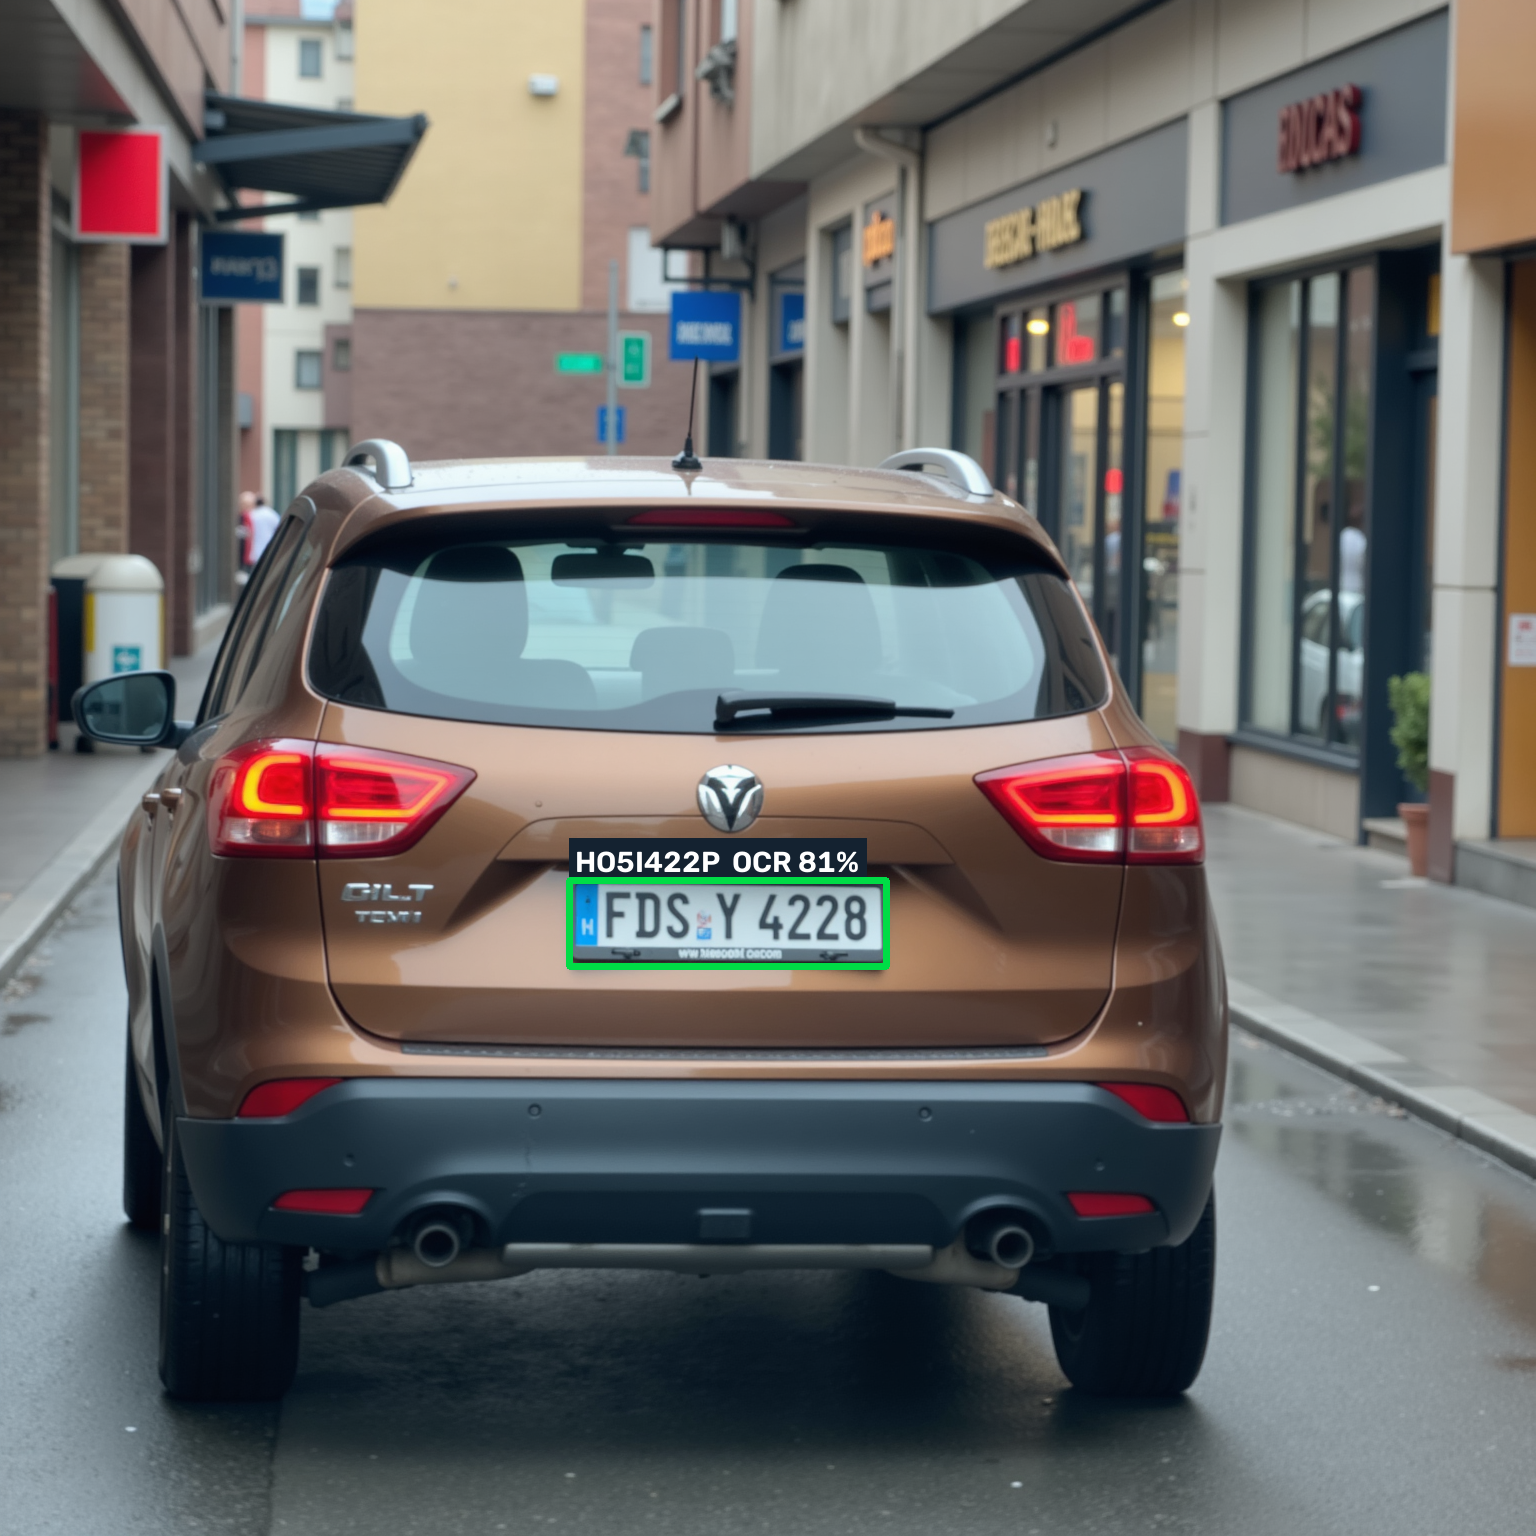

In [8]:
from model_inference import load_model as load_runtime_model, recognize_plate

load_runtime_model.cache_clear()
preview_candidates = list(detector_splits['test'])
random.Random(SEED+777).shuffle(preview_candidates)
preview_result = None
for image_path, _, _ in preview_candidates[:25]:
    bgr_image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if bgr_image is None:
        continue
    rgb_image = cv2.cvtColor(bgr_image, cv2.COLOR_BGR2RGB)
    plate_text, box_confidence, annotated, message = recognize_plate(rgb_image)
    if plate_text:
        preview_result = (plate_text, annotated, message)
        break

if preview_result:
    print(preview_result[2])
    display(Image.fromarray(preview_result[1]))
else:
    print('The detector did not find a plate in the first 25 test examples; inspect model metrics and try another sample.')